# Análise Exploratória de Dados — NWPU-RESISC45 (10 classes)

**Projeto:** Classificação de Cenas Aéreas com Redes Neurais · **Disciplina:** Ciência de Dados — Unidade III
**Etapa 2:** Análise Exploratória de Dados (EDA) · **Pré-requisito:** preparação inicial concluída (`scripts/preparar_dados.py`)

Este notebook caracteriza, de forma quantitativa e visual, o conjunto de 10 classes preparado em `dados/raw/`.

**Regras seguidas nesta análise**
- O inventário, as contagens, os formatos, as dimensões e as duplicatas consideram **todo o dataset** (7.000 imagens).
- Toda visualização de **conteúdo** das imagens (painéis, histogramas, descritores e resoluções) usa **somente a partição de treino** (`dados/splits/treino.csv`).
- Das partições de validação e teste, verificam-se apenas a integridade, as contagens e a ausência de sobreposição.
- Nenhum modelo é treinado ou avaliado.

As figuras são salvas em `resultados/figuras/eda/` e as tabelas em `resultados/tabelas/eda/`.

## 0. Configuração

In [1]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
DADOS = ROOT / "dados"
FIG = ROOT / "resultados" / "figuras" / "eda"
TAB = ROOT / "resultados" / "tabelas" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
CLASSES = ["airport", "beach", "circular_farmland", "dense_residential", "desert",
           "forest", "harbor", "mountain", "river", "storage_tank"]  # ordem da documentação do projeto
NOME_PT = {"airport": "Aeroporto", "beach": "Praia", "circular_farmland": "Área agrícola circular",
           "dense_residential": "Área residencial densa", "desert": "Deserto", "forest": "Floresta",
           "harbor": "Porto", "mountain": "Montanha", "river": "Rio", "storage_tank": "Tanques de armazenamento"}

COR = "#2a78d6"          # série única
TINTA, TINTA_2, GRADE = "#1f1f1e", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9a9993", "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "grid.color": GRADE, "grid.linewidth": 0.8,
})
pd.set_option("display.max_columns", 30, "display.width", 160)

def salvar(fig, nome):
    fig.savefig(FIG / nome, bbox_inches="tight")
    print("figura salva:", (FIG / nome).relative_to(ROOT).as_posix())

def abrir(rel):
    with Image.open(ROOT / rel) as im:
        return im.convert("RGB")

def mostrar(ax, img, titulo=None, rotulo=None):
    ax.imshow(img, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if titulo:
        ax.set_title(titulo, fontsize=7.5, fontweight="normal", color=TINTA_2, loc="center", pad=3)
    if rotulo:
        ax.set_ylabel(rotulo, rotation=0, ha="right", va="center", fontsize=10, fontweight="bold", labelpad=10)

print("Raiz do projeto:", ROOT)

Raiz do projeto: C:\Users\caioj\OneDrive\Área de Trabalho\facul\AV3_CienciaDados


### 0.1. Carregamento do inventário, do relatório de preparação e das partições

In [2]:
inv = pd.read_csv(DADOS / "inventario_arquivos.csv")
relatorio = pd.read_csv(DADOS / "relatorio_preparacao.csv")
ocorrencias = pd.read_csv(DADOS / "registro_ocorrencias.csv")
dup_exatas = pd.read_csv(DADOS / "duplicatas_exatas.csv")
quase_dup = pd.read_csv(DADOS / "candidatas_quase_duplicatas.csv")
part = pd.read_csv(DADOS / "splits" / "particoes.csv")
resumo_part = json.loads((DADOS / "splits" / "resumo_particoes.json").read_text(encoding="utf-8"))

treino = part[part.particao == "treino"].reset_index(drop=True)
print(f"Inventário: {len(inv)} arquivos | Partições: {part.particao.value_counts().to_dict()}")
print("Semente e proporções das partições:", resumo_part["semente"], resumo_part["proporcoes"])

Inventário: 7000 arquivos | Partições: {'treino': 4900, 'validacao': 1050, 'teste': 1050}
Semente e proporções das partições: 42 {'treino': 0.7, 'validacao': 0.15, 'teste': 0.15}


## 1. Distribuição das classes

Contagem de imagens por categoria a partir do inventário da preparação inicial (todo o dataset), participação percentual e comparação com o valor esperado (700).

In [3]:
freq = inv.groupby("classe").size().reindex(CLASSES)
validos = inv[inv.valido].groupby("classe").size().reindex(CLASSES)
tab_freq = pd.DataFrame({
    "classe": CLASSES,
    "nome": [NOME_PT[c] for c in CLASSES],
    "quantidade": freq.values,
    "validas": validos.values,
    "percentual": (100 * freq / freq.sum()).round(2).values,
    "esperado": 700,
})
tab_freq["diferenca"] = tab_freq.quantidade - tab_freq.esperado
tab_freq.loc[len(tab_freq)] = ["TOTAL", "", freq.sum(), validos.sum(), 100.0, 7000, freq.sum() - 7000]
tab_freq.to_csv(TAB / "frequencia_classes.csv", index=False)
display(tab_freq)

print("Exclusões realizadas na preparação:",
      json.loads((DADOS / "resumo_preparacao.json").read_text(encoding="utf-8"))["exclusoes_realizadas"])
print("Coeficiente de desequilíbrio (máx/mín):", freq.max() / freq.min())

,classe,nome,quantidade,validas,percentual,esperado,diferenca
0,airport,Aeroporto,700,700,10.0,700,0
1,beach,Praia,700,700,10.0,700,0
2,circular_farmland,Área agrícola circular,700,700,10.0,700,0
3,dense_residential,Área residencial densa,700,700,10.0,700,0
4,desert,Deserto,700,700,10.0,700,0
5,forest,Floresta,700,700,10.0,700,0
6,harbor,Porto,700,700,10.0,700,0
7,mountain,Montanha,700,700,10.0,700,0
8,river,Rio,700,700,10.0,700,0
9,storage_tank,Tanques de armazenamento,700,700,10.0,700,0


Exclusões realizadas na preparação: 0
Coeficiente de desequilíbrio (máx/mín): 1.0


figura salva: resultados/figuras/eda/distribuicao_classes.png


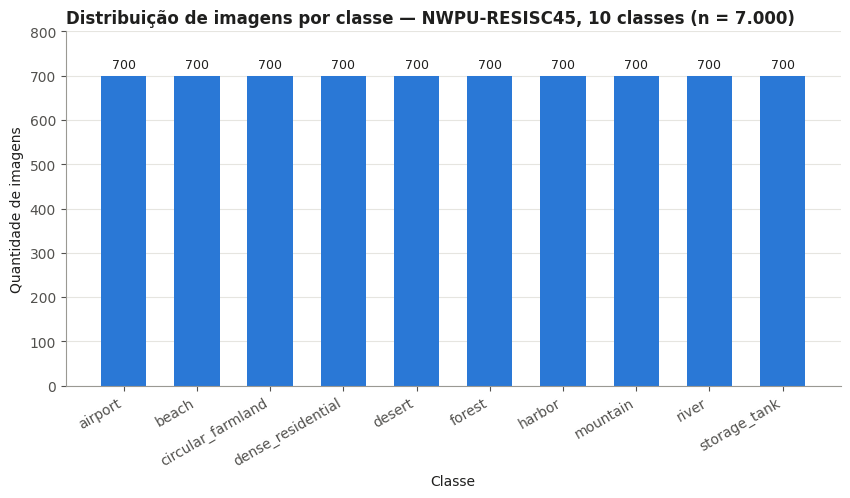

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(CLASSES))
ax.bar(x, freq.values, width=0.62, color=COR, zorder=2)
ax.yaxis.grid(True, zorder=0)
for xi, v in zip(x, freq.values):
    ax.text(xi, v + 10, f"{v}", ha="center", va="bottom", fontsize=9, color=TINTA)
ax.set_xticks(x, CLASSES, rotation=30, ha="right")
ax.set_ylim(0, 800)
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade de imagens")
n_fmt = f"{freq.sum():,}".replace(",", ".")
ax.set_title(f"Distribuição de imagens por classe — NWPU-RESISC45, 10 classes (n = {n_fmt})")
salvar(fig, "distribuicao_classes.png")
plt.show()

### 1.1. Distribuição por partição

Verificação das partições de validação e teste (apenas contagem, integridade e sobreposição).

In [5]:
tab_part = pd.crosstab(part.classe, part.particao).reindex(index=CLASSES, columns=["treino", "validacao", "teste"])
tab_part["total"] = tab_part.sum(axis=1)
tab_part.loc["TOTAL"] = tab_part.sum()
tab_part.to_csv(TAB / "distribuicao_particoes.csv")
display(tab_part)

conj = {p: set(part.loc[part.particao == p, "arquivo"]) for p in ["treino", "validacao", "teste"]}
print("Sobreposição treino∩validação:", len(conj["treino"] & conj["validacao"]),
      "| treino∩teste:", len(conj["treino"] & conj["teste"]),
      "| validação∩teste:", len(conj["validacao"] & conj["teste"]))
print("Todos os arquivos das partições existem e são válidos:",
      set(part.arquivo) <= set(inv.loc[inv.valido, "arquivo"]) and all((ROOT / a).is_file() for a in part.arquivo))
print("Grupos de duplicatas divididos entre partições:", resumo_part["grupos_divididos_entre_particoes"])

particao,treino,validacao,teste,total
classe,,,,
airport,490,105,105,700
beach,490,105,105,700
circular_farmland,490,105,105,700
dense_residential,490,105,105,700
desert,490,105,105,700
forest,490,105,105,700
harbor,490,105,105,700
mountain,490,105,105,700
river,490,105,105,700


Sobreposição treino∩validação: 0 | treino∩teste: 0 | validação∩teste: 0


Todos os arquivos das partições existem e são válidos: True
Grupos de duplicatas divididos entre partições: 0


### 1.2. Interpretação

- **Todas as classes têm a mesma quantidade de imagens?** Sim. As dez classes têm exatamente 700 imagens, ou seja, 10,0% do total cada uma. A razão entre a maior e a menor classe é 1,0.
- **Existem classes com arquivos ausentes?** Não. A diferença em relação ao esperado é zero em todas as classes, e as 7.000 imagens foram consideradas válidas na preparação.
- **A preparação inicial alterou a distribuição original?** Não. Nenhum arquivo foi excluído. As 6 duplicatas exatas (todas em `airport`) e a quase-duplicata confirmada (`mountain`) foram apenas registradas, e a decisão sobre elas ficou para uma etapa posterior. Se no futuro for mantida só uma cópia de cada par, `airport` passaria a ter 694 imagens e `mountain` 699, uma variação abaixo de 1% que não muda o equilíbrio.
- **O conjunto é equilibrado?** Sim, perfeitamente equilibrado. As partições preservam esse equilíbrio: 490, 105 e 105 imagens por classe em treino, validação e teste (70/15/15), sem sobreposição. Os pares duplicados ficaram sempre juntos na mesma partição: os de `airport` ficaram 4 pares no treino e 2 na validação, e o de `mountain` ficou no treino.

## 2. Características técnicas dos arquivos

Consolidação do inventário e do relatório da preparação inicial. As verificações de leitura, formato, dimensão e canais já foram feitas por `scripts/preparar_dados.py` e são apenas reutilizadas aqui.

In [6]:
propriedades = pd.DataFrame([
    ("Total de imagens", len(inv)),
    ("Imagens válidas", int(inv.valido.sum())),
    ("Imagens inválidas/corrompidas", int((~inv.valido).sum())),
    ("Formatos", ", ".join(f"{k} ({v})" for k, v in inv.formato.value_counts().items())),
    ("Dimensões (L × A)", ", ".join(f"{w}×{h} ({n})" for (w, h), n in inv.groupby(["largura", "altura"]).size().items())),
    ("Modo de cor", ", ".join(f"{k} ({v})" for k, v in inv.modo.value_counts().items())),
    ("Canais", ", ".join(f"{k} ({v})" for k, v in inv.canais.value_counts().items())),
    ("Cópias idênticas ao original (SHA-256)", int((inv.copia_identica_original == "sim").sum())),
    ("Tamanho em disco: total (MB)", round(inv.bytes.sum() / 2**20, 1)),
    ("Tamanho por arquivo: mín / mediana / máx (KB)",
     f"{inv.bytes.min()/1024:.1f} / {inv.bytes.median()/1024:.1f} / {inv.bytes.max()/1024:.1f}"),
    ("Duplicatas exatas (grupos / arquivos)", f"{dup_exatas.grupo.nunique()} / {len(dup_exatas)}"),
    ("Quase-duplicatas confirmadas (pares)", int(quase_dup.avaliacao.str.startswith("quase_duplicata").sum())),
], columns=["propriedade", "valor"])
propriedades.to_csv(TAB / "propriedades_tecnicas.csv", index=False)
display(propriedades)

,propriedade,valor
0,Total de imagens,7000
1,Imagens válidas,7000
2,Imagens inválidas/corrompidas,0
3,Formatos,JPEG (7000)
4,Dimensões (L × A),256×256 (7000)
5,Modo de cor,RGB (7000)
6,Canais,3 (7000)
7,Cópias idênticas ao original (SHA-256),7000
8,Tamanho em disco: total (MB),90.6
9,Tamanho por arquivo: mín / mediana / máx (KB),3.8 / 13.0 / 24.5


In [7]:
print("Relatório da preparação inicial:")
display(relatorio)
print("Ocorrências registradas por tipo:")
display(ocorrencias.groupby("tipo").size().rename("ocorrencias").to_frame())
print("Duplicatas exatas (todas na classe airport) e quase-duplicatas avaliadas:")
display(dup_exatas.groupby("grupo").agg(classe=("classe", "first"),
                                        arquivos=("arquivo", lambda s: " = ".join(Path(a).name for a in s))))
display(quase_dup[["arquivo_a", "arquivo_b", "distancia_dhash", "diferenca_media_pixel", "avaliacao"]])
dup_part = part[part.tamanho_grupo > 1].groupby(["classe", "particao"]).size().rename("arquivos").to_frame()
print("Partição em que ficaram os arquivos duplicados (pares sempre juntos):")
display(dup_part)

Relatório da preparação inicial:


,classe,quantidade_esperada,quantidade_encontrada,diferenca,arquivos_validos,arquivos_invalidos,duplicatas_exatas,status
0,airport,700,700,0,700,0,12,OK_COM_DUPLICATAS
1,beach,700,700,0,700,0,0,OK
2,circular_farmland,700,700,0,700,0,0,OK
3,dense_residential,700,700,0,700,0,0,OK
4,desert,700,700,0,700,0,0,OK
5,forest,700,700,0,700,0,0,OK
6,harbor,700,700,0,700,0,0,OK
7,mountain,700,700,0,700,0,0,OK
8,river,700,700,0,700,0,0,OK
9,storage_tank,700,700,0,700,0,0,OK


Ocorrências registradas por tipo:


,ocorrencias
tipo,
candidata_quase_duplicata,3
duplicata_exata,6


Duplicatas exatas (todas na classe airport) e quase-duplicatas avaliadas:


,classe,arquivos
grupo,,
1,airport,airport_118.jpg = airport_315.jpg
2,airport,airport_050.jpg = airport_420.jpg
3,airport,airport_243.jpg = airport_397.jpg
4,airport,airport_361.jpg = airport_509.jpg
5,airport,airport_064.jpg = airport_527.jpg
6,airport,airport_289.jpg = airport_635.jpg


,arquivo_a,arquivo_b,distancia_dhash,diferenca_media_pixel,avaliacao
0,dados/raw/mountain/mountain_111.jpg,dados/raw/mountain/mountain_324.jpg,0,0.034,"quase_duplicata_confirmada (mesma cena, recodi..."
1,dados/raw/beach/beach_106.jpg,dados/raw/desert/desert_318.jpg,2,44.258,falso_positivo (cenas distintas)
2,dados/raw/beach/beach_106.jpg,dados/raw/beach/beach_592.jpg,3,34.800,falso_positivo (cenas distintas)


Partição em que ficaram os arquivos duplicados (pares sempre juntos):


arquivos
classe   particao           
airport  treino            8
         validacao         4
mountain treino            2

O tamanho do arquivo JPEG é um indicador indireto da complexidade visual: com a mesma resolução e o mesmo formato, imagens com mais textura e bordas comprimem menos.

figura salva: resultados/figuras/eda/tamanho_arquivos.png


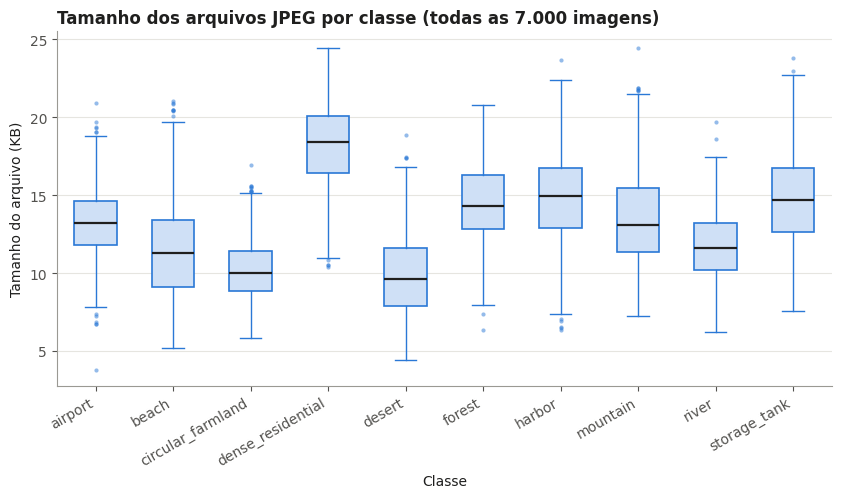

,media_KB,mediana_KB,min_KB,max_KB
classe,,,,
airport,13.2,13.2,3.8,20.9
beach,11.5,11.3,5.2,21.0
circular_farmland,10.3,10.0,5.8,16.9
dense_residential,18.1,18.4,10.4,24.5
desert,9.9,9.6,4.4,18.8
forest,14.6,14.3,6.3,20.8
harbor,14.8,14.9,6.3,23.7
mountain,13.6,13.1,7.2,24.4
river,11.7,11.6,6.2,19.7


In [8]:
fig, ax = plt.subplots(figsize=(10, 4.6))
dados_kb = [inv.loc[inv.classe == c, "bytes"].values / 1024 for c in CLASSES]
bp = ax.boxplot(dados_kb, widths=0.55, patch_artist=True, showfliers=True,
                medianprops=dict(color=TINTA, linewidth=1.6),
                boxprops=dict(facecolor="#cfe0f6", edgecolor=COR, linewidth=1.2),
                whiskerprops=dict(color=COR), capprops=dict(color=COR),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=COR, markeredgecolor="none", alpha=.5))
ax.set_xticks(np.arange(1, 11), CLASSES, rotation=30, ha="right")
ax.yaxis.grid(True, zorder=0)
ax.set_ylabel("Tamanho do arquivo (KB)")
ax.set_xlabel("Classe")
ax.set_title("Tamanho dos arquivos JPEG por classe (todas as 7.000 imagens)")
salvar(fig, "tamanho_arquivos.png")
plt.show()
display(inv.groupby("classe").bytes.describe().reindex(CLASSES).div(1024).round(1)[["mean", "50%", "min", "max"]]
        .rename(columns={"mean": "media_KB", "50%": "mediana_KB", "min": "min_KB", "max": "max_KB"}))

### 2.1. Interpretação

- **Imagens válidas:** 7.000 de 7.000. Nenhum arquivo está corrompido, vazio ou ilegível, e todas as cópias são idênticas, byte a byte, aos originais.
- **Formato:** todas as imagens são JPEG, com extensão `.jpg`.
- **Dimensões:** todas têm exatamente 256 × 256 pixels, então não há variação de resolução entre os arquivos.
- **Canais de cor:** todas estão em modo RGB, com 3 canais de 8 bits (0–255). Não há imagens em tons de cinza, com transparência (RGBA) ou em paleta.
- **Ocorrências da preparação:** há 6 pares de duplicatas exatas em `airport` e 1 quase-duplicata em `mountain` (`mountain_111`/`mountain_324`, a mesma cena salva duas vezes). Também foram descartados 2 falsos positivos de quase-duplicata, envolvendo `beach_106`. **Nenhuma inconsistência pendente** impede a análise. O único ponto em aberto é a decisão de manter ou remover as duplicatas, o que não afeta o conteúdo das partições, já que os pares estão agrupados.
- **Tamanho dos arquivos:** o conjunto ocupa 90,6 MB, com mediana de 13,0 KB por imagem. Como resolução e formato são iguais para todas, a diferença de tamanho reflete a complexidade visual. `dense_residential` tem os maiores arquivos (mediana de 18,4 KB, com muitas bordas e telhados), enquanto `desert` (9,6 KB) e `circular_farmland` (10,0 KB) têm os menores, por terem grandes áreas homogêneas. Esse resultado antecipa o que os descritores de textura das seções 4 e 6 confirmam.

## 3. Visualização das categorias (somente treino)

Cinco imagens por classe sorteadas da partição de treino com semente fixa. A legenda de cada imagem é o nome do arquivo, que também contém a classe.

figura salva: resultados/figuras/eda/exemplos_classes.png


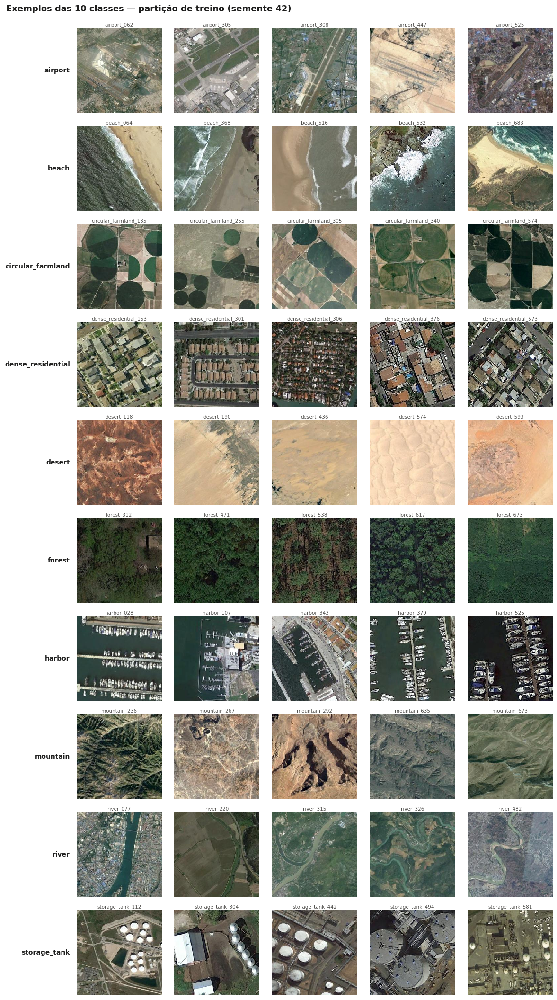

In [9]:
rng = np.random.default_rng(SEMENTE)
N_EX = 5
amostra = {c: sorted(rng.choice(treino.loc[treino.classe == c, "arquivo"].values, N_EX, replace=False)) for c in CLASSES}
assert all(a in conj["treino"] for v in amostra.values() for a in v)

fig, axs = plt.subplots(len(CLASSES), N_EX, figsize=(N_EX * 2.1 + 1.6, len(CLASSES) * 2.15))
for i, c in enumerate(CLASSES):
    for j, rel in enumerate(amostra[c]):
        mostrar(axs[i, j], abrir(rel), Path(rel).stem, rotulo=c if j == 0 else None)
fig.suptitle("Exemplos das 10 classes — partição de treino (semente 42)", x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.985))
salvar(fig, "exemplos_classes.png")
plt.show()

### 3.1. Características visuais observadas

| Classe | O que foi observado nos exemplos de treino |
|---|---|
| **airport** | Pistas longas e retilíneas, pátios e terminais com edificações grandes. O entorno varia muito: areia (`airport_447`), área urbana densa (`airport_525`), campos verdes (`airport_308`). A pista às vezes ocupa uma fração pequena da imagem. |
| **beach** | Transição água → espuma branca → areia em uma faixa contínua, com orientação variável (diagonal, vertical). A água vai do verde-escuro ao azul, e há costões rochosos (`beach_532`). |
| **circular_farmland** | Círculos de pivô central com diâmetros parecidos, verde-escuros ou bege conforme a cultura, repetidos em grade e separados por estradas retas. É a classe com geometria mais regular. |
| **dense_residential** | Telhados muito próximos (vermelhos, cinza, bege), ruas em grade ou curvas, carros e árvores entre as casas. Tem a textura mais fina e densa do conjunto. |
| **desert** | Superfícies arenosas homogêneas, com ondulações de dunas e tons quentes (bege a laranja), quase sem vegetação. Também aparecem terrenos rochosos avermelhados (`desert_118`), que lembram montanhas áridas. |
| **forest** | Cobertura contínua de copas verde-escuras, com textura granulada e uniforme. Algumas imagens mostram sombras alongadas das árvores ou fileiras de plantio (`forest_538`). |
| **harbor** | Água escura com muitos barcos brancos alinhados ao longo de píeres paralelos. É um padrão repetitivo e muito característico, quase sempre com área urbana ou cais ao lado. |
| **mountain** | Cristas, vales e sombras de relevo, com redes de drenagem ramificadas. A cobertura varia de vegetada (verde, `mountain_236`) a árida e rochosa (`mountain_292`, avermelhada). |
| **river** | Um canal alongado e sinuoso que atravessa a cena, com margens agrícolas, de vegetação ou urbanas. A largura varia muito: em `river_220` o rio é um fio estreito e difícil de ver. |
| **storage_tank** | Círculos pequenos e brancos (tetos dos tanques) com sombra lateral, agrupados e cercados de infraestrutura industrial (tubulações, vias, galpões). O tamanho dos tanques varia de imagem para imagem. |

**Padrões gerais.** Há dois grupos bem distintos: classes **construídas**, com formas geométricas reconhecíveis (pistas, círculos, telhados, píeres), e classes **naturais**, definidas sobretudo por textura e cor (floresta, deserto, montanha). Formas circulares aparecem em duas classes, mas em escalas muito diferentes (pivôs grandes × tanques pequenos). Formas lineares aparecem em `airport` (retas) e `river` (sinuosas). Dentro de cada classe, a diversidade é grande: o mesmo tipo de cena aparece com orientações, escalas, estações e entornos diferentes.

## 4. Descritores simples de cor e textura (somente treino)

Para apoiar as análises seguintes com números, e não só com impressões visuais, calcula-se para cada imagem de treino um conjunto de descritores. **Esses descritores não são um modelo e não são usados para classificar nada.**

| Descritor | Definição |
|---|---|
| `media_R/G/B` | média de cada canal (0–255) |
| `brilho` | média da luminância (L, 0–255) |
| `contraste` | desvio-padrão da luminância |
| `saturacao` | média do canal S do HSV (0–1) |
| `gradiente` | magnitude média do gradiente da luminância: indicador de bordas e textura |
| `perda_detalhe_128` | diferença absoluta média (em L) entre a imagem original e sua versão reduzida para 128×128 e reampliada para 256×256 |
| histograma | 16 *bins* por canal RGB + 16 *bins* de magnitude do gradiente, normalizados (usado nas distâncias entre classes) |

In [10]:
BINS_RGB = 256
hist_rgb = {c: np.zeros((3, BINS_RGB)) for c in CLASSES}
hist_lum = {c: np.zeros(256) for c in CLASSES}
linhas, descritores = [], []

def janela_mais_detalhada(g, lado=64, passo=32):
    # canto superior esquerdo da janela lado×lado de maior gradiente médio
    gy, gx = np.gradient(g)
    mag = np.hypot(gx, gy)
    melhor, pos = -1, (0, 0)
    for y in range(0, g.shape[0] - lado + 1, passo):
        for x in range(0, g.shape[1] - lado + 1, passo):
            v = mag[y:y + lado, x:x + lado].mean()
            if v > melhor:
                melhor, pos = v, (y, x)
    return pos

for rel, c in zip(treino.arquivo, treino.classe):
    im = abrir(rel)
    a = np.asarray(im)
    L_img = im.convert("L")
    L = np.asarray(L_img, dtype=np.float32)
    S = np.asarray(im.convert("HSV"))[..., 1] / 255.0
    gy, gx = np.gradient(L)
    mag = np.hypot(gx, gy)
    reduzida = L_img.resize((128, 128), Image.Resampling.LANCZOS).resize((256, 256), Image.Resampling.BICUBIC)
    perda = np.abs(L - np.asarray(reduzida, dtype=np.float32)).mean()

    h = np.stack([np.bincount(a[..., k].ravel(), minlength=256) for k in range(3)])
    hist_rgb[c] += h
    hist_lum[c] += np.bincount(np.asarray(L_img).ravel(), minlength=256)

    h16 = h.reshape(3, 16, 16).sum(axis=2) / a[..., 0].size / 3          # bloco de cor soma 1
    hg = np.histogram(np.clip(mag, 0, 79.99), bins=16, range=(0, 80))[0] / mag.size  # bloco de textura soma 1
    descritores.append(np.concatenate([h16.ravel(), hg]))
    linhas.append(dict(arquivo=rel, classe=c, media_R=float(a[..., 0].mean()), media_G=float(a[..., 1].mean()),
                       media_B=float(a[..., 2].mean()), brilho=float(L.mean()), contraste=float(L.std()),
                       saturacao=float(S.mean()), gradiente=float(mag.mean()), perda_detalhe_128=float(perda)))

est = pd.DataFrame(linhas)
X = np.vstack(descritores)
est.to_csv(TAB / "descritores_treino.csv", index=False)
por_classe = est.groupby("classe")[["media_R", "media_G", "media_B", "brilho", "contraste",
                                     "saturacao", "gradiente", "perda_detalhe_128"]].mean().reindex(CLASSES)
por_classe.round(3).to_csv(TAB / "descritores_por_classe.csv")
print(f"{len(est)} imagens de treino processadas")
display(por_classe.round(2))

4900 imagens de treino processadas


,media_R,media_G,media_B,brilho,contraste,saturacao,gradiente,perda_detalhe_128
classe,,,,,,,,
airport,114.09,116.09,103.95,114.11,33.78,0.16,10.35,4.64
beach,112.94,121.30,112.37,117.78,41.68,0.23,8.66,4.32
circular_farmland,100.17,107.02,89.13,102.93,31.79,0.23,6.54,2.98
dense_residential,84.71,86.17,78.46,84.86,42.89,0.17,17.47,8.92
desert,186.55,158.34,128.45,163.37,17.40,0.30,6.40,2.70
forest,48.42,57.96,43.56,53.47,21.84,0.30,11.76,5.77
harbor,74.74,80.10,75.87,78.01,47.32,0.20,15.16,7.83
mountain,98.29,99.08,82.58,96.96,27.95,0.24,10.53,4.74
river,85.45,97.13,82.85,92.01,28.98,0.25,8.16,3.62


### 4.1. Distância entre classes pelos descritores

Distância L1 entre o descritor médio (histograma de cor e textura) de cada par de classes, em uma escala de 0 a 2. Quanto menor a distância, mais parecidas as duas classes são **nesses descritores simples**. Isso não indica, por si só, dificuldade de classificação.

figura salva: resultados/figuras/eda/distancia_classes.png


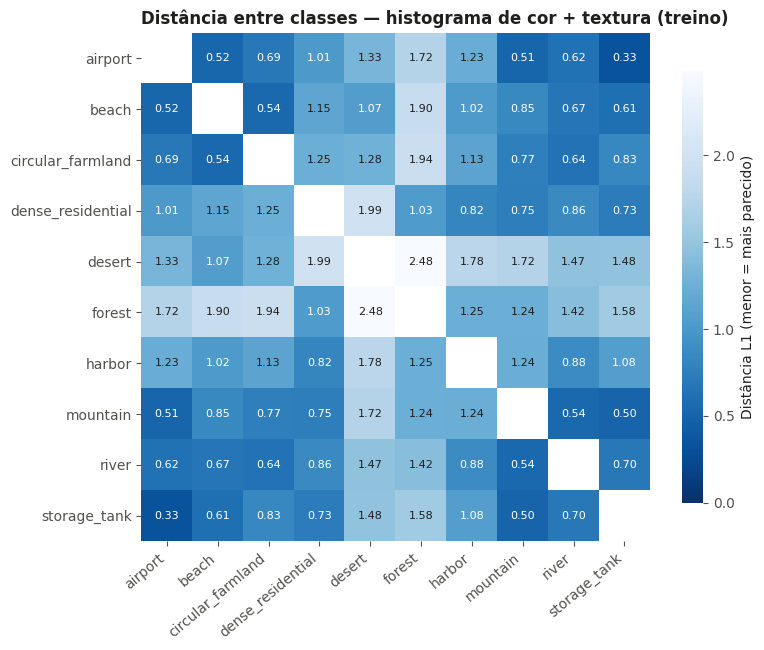

10 pares de classes mais próximos (de 45):


,classe_a,classe_b,distancia
1,airport,storage_tank,0.332
2,mountain,storage_tank,0.501
3,airport,mountain,0.513
4,airport,beach,0.518
5,beach,circular_farmland,0.537
6,mountain,river,0.539
7,beach,storage_tank,0.610
8,airport,river,0.623
9,circular_farmland,river,0.636
10,beach,river,0.675


In [11]:
centro = np.vstack([X[(est.classe == c).values].mean(axis=0) for c in CLASSES])
D = np.abs(centro[:, None, :] - centro[None, :, :]).sum(axis=2)
dist = pd.DataFrame(D, index=CLASSES, columns=CLASSES)
dist.round(3).to_csv(TAB / "distancia_classes.csv")

fig, ax = plt.subplots(figsize=(8.2, 7))
M = np.ma.masked_where(np.eye(len(CLASSES), dtype=bool), D)
cmap = plt.get_cmap("Blues_r").copy(); cmap.set_bad("white")
im = ax.imshow(M, cmap=cmap, vmin=0, vmax=D.max())
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if i != j:
            ax.text(j, i, f"{D[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if D[i, j] < D.max() * 0.45 else TINTA)
ax.set_xticks(range(10), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(10), CLASSES)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Distância L1 (menor = mais parecido)"); cb.outline.set_visible(False)
ax.set_title("Distância entre classes — histograma de cor + textura (treino)")
salvar(fig, "distancia_classes.png")
plt.show()

pares = [(CLASSES[i], CLASSES[j], D[i, j]) for i in range(10) for j in range(i + 1, 10)]
ranking = pd.DataFrame(sorted(pares, key=lambda t: t[2]), columns=["classe_a", "classe_b", "distancia"])
ranking.index = ranking.index + 1
ranking.to_csv(TAB / "ranking_pares_classes.csv", index_label="posicao")
print("10 pares de classes mais próximos (de 45):")
display(ranking.head(10).round(3))

## 5. Investigação de ambiguidades visuais (somente treino)

Para cada par sugerido na documentação, selecionam-se de forma reprodutível as **4 imagens de treino de cada classe cujo descritor está mais próximo do descritor médio da outra classe**. São, portanto, os exemplos que mais "se parecem" com a outra categoria. Em seguida, são comparadas as médias dos descritores das duas classes.

figura salva: resultados/figuras/eda/ambiguidades_visuais.png


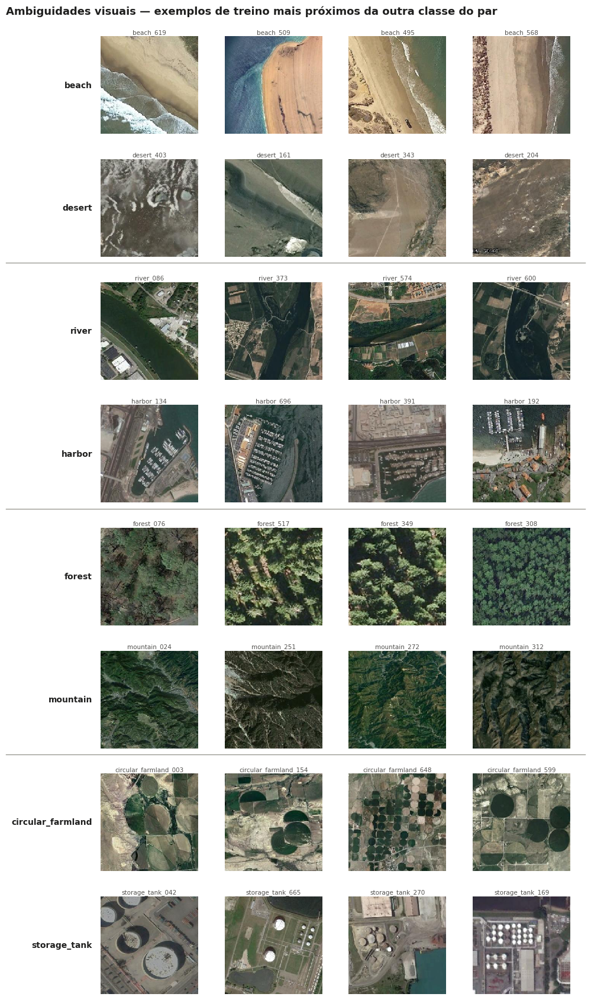

,par,classe,brilho,contraste,saturacao,gradiente,media_R,media_G,media_B
0,beach × desert,beach,117.78,41.68,0.23,8.66,112.94,121.3,112.37
1,beach × desert,desert,163.37,17.4,0.3,6.4,186.55,158.34,128.45
2,beach × desert,distância (posição),1.066 (24º de 45),,,,,,
3,river × harbor,river,92.01,28.98,0.25,8.16,85.45,97.13,82.85
4,river × harbor,harbor,78.01,47.32,0.2,15.16,74.74,80.1,75.87
5,river × harbor,distância (posição),0.881 (20º de 45),,,,,,
6,forest × mountain,forest,53.47,21.84,0.3,11.76,48.42,57.96,43.56
7,forest × mountain,mountain,96.96,27.95,0.24,10.53,98.29,99.08,82.58
8,forest × mountain,distância (posição),1.243 (30º de 45),,,,,,
9,circular_farmland × storage_tank,circular_farmland,102.93,31.79,0.23,6.54,100.17,107.02,89.13


In [12]:
PARES_AMB = [("beach", "desert"), ("river", "harbor"), ("forest", "mountain"), ("circular_farmland", "storage_tank")]
N_AMB = 4
idx = {c: np.where((est.classe == c).values)[0] for c in CLASSES}
pos = {c: i for i, c in enumerate(CLASSES)}

def mais_proximas(origem, alvo, n=N_AMB):
    d = np.abs(X[idx[origem]] - centro[pos[alvo]]).sum(axis=1)
    return est.arquivo.values[idx[origem][np.argsort(d)[:n]]]

selecao = {(a, b): (mais_proximas(a, b), mais_proximas(b, a)) for a, b in PARES_AMB}

fig, axs = plt.subplots(2 * len(PARES_AMB), N_AMB, figsize=(N_AMB * 2.1 + 1.8, 2 * len(PARES_AMB) * 2.15))
for k, (a, b) in enumerate(PARES_AMB):
    for r, (classe, arqs) in enumerate(zip((a, b), selecao[(a, b)])):
        for j, rel in enumerate(arqs):
            mostrar(axs[2 * k + r, j], abrir(rel), Path(rel).stem, rotulo=classe if j == 0 else None)
fig.suptitle("Ambiguidades visuais — exemplos de treino mais próximos da outra classe do par",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.985), h_pad=2.2)
for k in range(1, len(PARES_AMB)):  # separador entre comparações
    y = axs[2 * k - 1, 0].get_position().y0 - 0.006  # logo abaixo da linha superior, acima dos títulos seguintes
    fig.add_artist(plt.Line2D([0.02, 0.98], [y, y], color="#9a9993", linewidth=1))
salvar(fig, "ambiguidades_visuais.png")
plt.show()

cols = ["brilho", "contraste", "saturacao", "gradiente", "media_R", "media_G", "media_B"]
comp = []
for a, b in PARES_AMB:
    for c in (a, b):
        comp.append({"par": f"{a} × {b}", "classe": c, **por_classe.loc[c, cols].round(2).to_dict()})
    comp.append({"par": f"{a} × {b}", "classe": "distância (posição)",
                 "brilho": f"{dist.loc[a, b]:.3f} ({int(ranking[((ranking.classe_a == a) & (ranking.classe_b == b)) | ((ranking.classe_a == b) & (ranking.classe_b == a))].index[0])}º de 45)"})
comp = pd.DataFrame(comp)
comp.to_csv(TAB / "ambiguidades_descritores.csv", index=False)
display(comp.fillna(""))

In [13]:
# Painéis individuais por par (úteis para o artigo/apresentação)
for a, b in PARES_AMB:
    fig, axs = plt.subplots(2, N_AMB, figsize=(N_AMB * 2.1 + 1.8, 2 * 2.2))
    for r, (classe, arqs) in enumerate(zip((a, b), selecao[(a, b)])):
        for j, rel in enumerate(arqs):
            mostrar(axs[r, j], abrir(rel), Path(rel).stem, rotulo=classe if j == 0 else None)
    fig.suptitle(f"{a} × {b} — exemplos de treino", x=0.02, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    salvar(fig, f"ambiguidade_{a}_x_{b}.png")
    plt.close(fig)

figura salva: resultados/figuras/eda/ambiguidade_beach_x_desert.png


figura salva: resultados/figuras/eda/ambiguidade_river_x_harbor.png


figura salva: resultados/figuras/eda/ambiguidade_forest_x_mountain.png


figura salva: resultados/figuras/eda/ambiguidade_circular_farmland_x_storage_tank.png


### 5.1. Praia × Deserto

- **Semelhanças:** as praias mais próximas de deserto têm uma faixa de areia ocupando quase toda a imagem e pouca vegetação (`beach_495`, `beach_568`). Os desertos mais próximos de praia são acinzentados ou amarronzados, com manchas claras que lembram espuma (`desert_403`) ou com o que parece uma margem de água (`desert_161`).
- **Diferenças:** a praia quase sempre tem **água e a linha branca de arrebentação** formando uma fronteira linear. O deserto não tem água e mostra ondulações de dunas. Em números, o deserto é bem mais claro (brilho médio 163 contra 118), mais quente (R 187 > G 158 > B 128) e muito mais homogêneo (contraste 17 contra 42).
- **Distância pelos descritores:** 1,07, o 24º par mais próximo de 45. No geral, as classes são bem separadas por cor. A semelhança fica concentrada em um subconjunto: praias dominadas por areia e desertos de tons apagados.
- **Hipótese:** imagens de praia em que a água ocupa pouco espaço podem se confundir com deserto. Isso não pode ser confirmado nesta etapa.

### 5.2. Rio × Porto

- **Semelhanças:** as duas classes têm grandes áreas de água escura. Os rios mais próximos de porto são largos, escuros e têm margens urbanizadas ou industriais (`river_086`, `river_574`). Os portos mais próximos de rio têm bacias alongadas cercadas de construções (`harbor_134`, `harbor_391`).
- **Diferenças:** o porto tem **barcos e píeres em padrões repetitivos**, e por isso o gradiente médio é quase o dobro do rio (15,2 contra 8,2). O rio é um canal contínuo que atravessa a cena e costuma ter margens agrícolas ou com vegetação. O porto também é mais escuro e mais contrastado (brilho 78 contra 92, contraste 47 contra 29), pois tem água escura com barcos brancos.
- **Distância pelos descritores:** 0,88 (20º de 45).
- **Hipótese:** rios largos em área urbana e portos sem muitos barcos visíveis podem ser difíceis de distinguir, sobretudo se os barcos ficarem pouco nítidos (ver seção 6).

### 5.3. Floresta × Montanha

- **Semelhanças:** as montanhas mais próximas de floresta são as **totalmente cobertas de vegetação** (`mountain_024`, `mountain_272`), com tom verde-escuro e textura de copas. As florestas mais próximas de montanha mostram sombras de árvores que criam uma aparência de relevo (`forest_349`, `forest_517`).
- **Diferenças:** a montanha tem estrutura em **escala grande**: cristas, vales, linhas de drenagem ramificadas e faixas de sombra que cruzam a imagem. A floresta tem textura fina e repetitiva de copas, sem essa organização maior. A floresta também é muito mais escura (brilho 53 contra 97) e é a classe mais homogênea do conjunto (desvio do brilho de 8,6 contra 25,7).
- **Distância pelos descritores:** 1,24 (30º de 45). Na média, as classes ficam bem separadas porque `mountain` inclui muitas cenas áridas. A ambiguidade aparece no subconjunto de montanhas vegetadas.
- **Hipótese:** montanhas vegetadas podem ser confundidas com floresta se o padrão de relevo não for percebido.

### 5.4. Área agrícola circular × Tanques de armazenamento

- **Semelhanças:** as duas classes têm **formas circulares** como elemento principal. As áreas agrícolas mais próximas de tanques têm vários pivôs pequenos ou fundo árido com construções (`circular_farmland_648`). Os tanques mais próximos de área agrícola são grandes, com anel escuro ao redor (`storage_tank_042`), ou ficam em terreno aberto (`storage_tank_665`).
- **Diferenças:** a principal é a **escala**. Um pivô ocupa uma fração grande da imagem (cerca de 1/4 a 1/2 do lado), enquanto um tanque costuma ter poucos pixels de diâmetro e aparece em grupo. Os tanques têm teto branco, sombra projetada e infraestrutura industrial ao redor. Os pivôs são verdes ou bege, com textura de cultivo, e separados por estradas retas. Os tanques também têm mais bordas (gradiente 13,2 contra 6,5) e menos saturação de cor (0,15 contra 0,23).
- **Distância pelos descritores:** 0,83 (17º de 45).
- **Hipótese:** tanques muito grandes ou pivôs muito pequenos e numerosos reduzem a diferença de escala, que é a principal pista para separar as classes.

### 5.5. Outros pares próximos sugeridos pelos descritores

A matriz de distâncias aponta pares **mais próximos** do que os quatro sugeridos na documentação:

- **airport × storage_tank (0,33, o par mais próximo):** as duas classes são áreas pavimentadas e industriais em cinza, com as menores saturações do conjunto (0,16 e 0,15) e brilho parecido (114 e 111). Elas se distinguem pela **forma**: pistas longas e retas contra círculos pequenos agrupados. Essa informação de forma não está nos histogramas.
- **mountain × storage_tank (0,50) e airport × mountain (0,51):** a proximidade vem de tons terrosos ou acinzentados e de textura intermediária, e não de semelhança visual real.
- **desert × mountain:** a distância média é grande (1,72), mas os painéis mostram desertos rochosos avermelhados (`desert_118`) muito parecidos com montanhas áridas (`mountain_292`).
- **airport × desert:** o menor arquivo de treino, `airport_512` (seção 7.4), é uma pista isolada sobre areia, e quase toda a imagem é visualmente deserto.

**Limitação:** os descritores usados aqui resumem só cor e intensidade de bordas da imagem inteira, sem considerar a disposição espacial. Por isso eles exageram a semelhança entre classes que diferem principalmente pela forma (airport × storage_tank) e subestimam ambiguidades que aparecem só em parte das imagens (forest × mountain, desert × mountain). As distâncias servem para orientar a inspeção visual e não indicam, por si só, dificuldade de classificação.

## 6. Comparação visual entre resoluções: 256 × 256 vs. 128 × 128 (somente treino)

A mesma imagem é carregada do arquivo original (256 × 256) e reduzida para 128 × 128 com filtro Lanczos, que suaviza a imagem antes de reduzir e evita serrilhado. Para a comparação ser justa, as duas versões aparecem **no mesmo tamanho na tela**: a de 128 × 128 é ampliada por vizinho mais próximo, sem criar informação nova, de modo que cada pixel dela vira um bloco de 2 × 2. As duas colunas da direita ampliam o trecho de maior detalhe da imagem, marcado em amarelo.

Critério de escolha: para cada classe, a imagem de treino cuja `perda_detalhe_128` está mais próxima da mediana da classe, ou seja, uma imagem típica e não um caso extremo.

figura salva: resultados/figuras/eda/comparacao_resolucoes.png


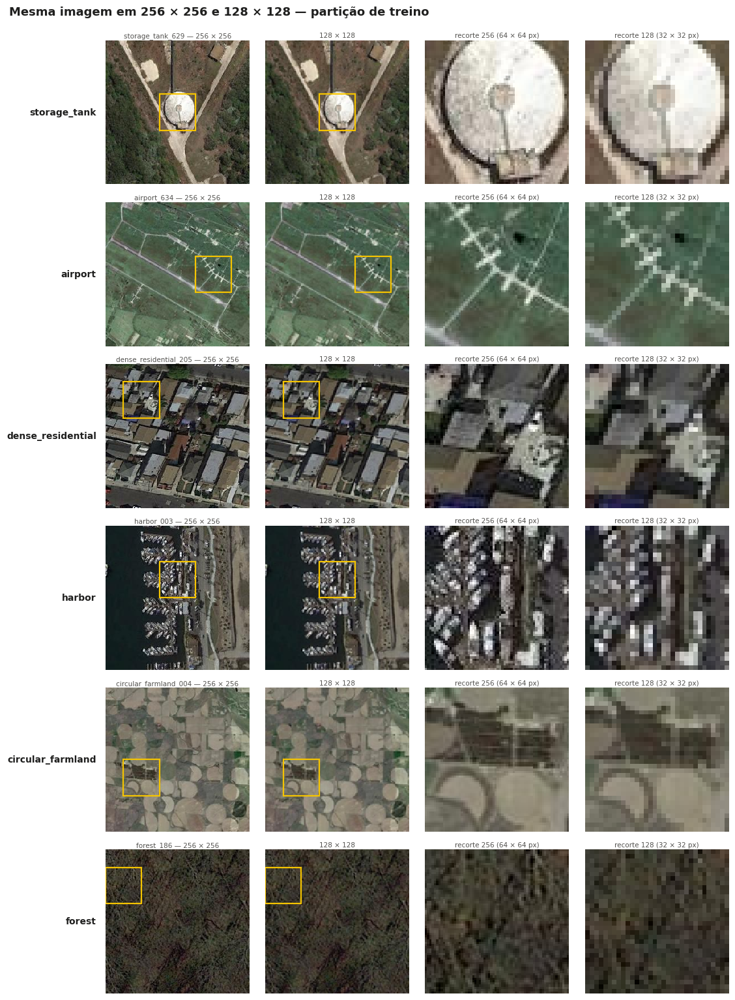

In [14]:
CLASSES_RES = ["storage_tank", "airport", "dense_residential", "harbor", "circular_farmland", "forest"]
escolhidas = []
for c in CLASSES_RES:
    sub = est[est.classe == c]
    escolhidas.append(sub.iloc[(sub.perda_detalhe_128 - sub.perda_detalhe_128.median()).abs().argsort().iloc[0]].arquivo)

fig, axs = plt.subplots(len(escolhidas), 4, figsize=(4 * 2.5 + 1.6, len(escolhidas) * 2.6))
for i, rel in enumerate(escolhidas):
    orig = abrir(rel)
    r128 = orig.resize((128, 128), Image.Resampling.LANCZOS)
    assert orig.size == (256, 256) and r128.size == (128, 128)
    y, x = janela_mais_detalhada(np.asarray(orig.convert("L"), dtype=np.float32))
    classe = rel.split("/")[2]
    mostrar(axs[i, 0], orig, f"{Path(rel).stem} — 256 × 256" if True else None, rotulo=classe)
    mostrar(axs[i, 1], r128.resize((256, 256), Image.Resampling.NEAREST), "128 × 128")
    mostrar(axs[i, 2], np.asarray(orig)[y:y + 64, x:x + 64], "recorte 256 (64 × 64 px)")
    mostrar(axs[i, 3], np.asarray(r128)[y // 2:y // 2 + 32, x // 2:x // 2 + 32], "recorte 128 (32 × 32 px)")
    for ax in axs[i, :2]:
        ax.add_patch(Rectangle((x - .5, y - .5), 64, 64, fill=False, edgecolor="#f5c400", linewidth=1.6))
fig.suptitle("Mesma imagem em 256 × 256 e 128 × 128 — partição de treino", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.985))
salvar(fig, "comparacao_resolucoes.png")
plt.show()

Medida complementar: o quanto de detalhe fino cada classe perde na redução. A medida é a diferença média em luminância entre a imagem original e a sua versão reduzida para 128 × 128 e reampliada. Valores maiores indicam mais estruturas pequenas e bordas que a resolução de 128 × 128 não consegue representar.

figura salva: resultados/figuras/eda/perda_detalhe_resolucao.png


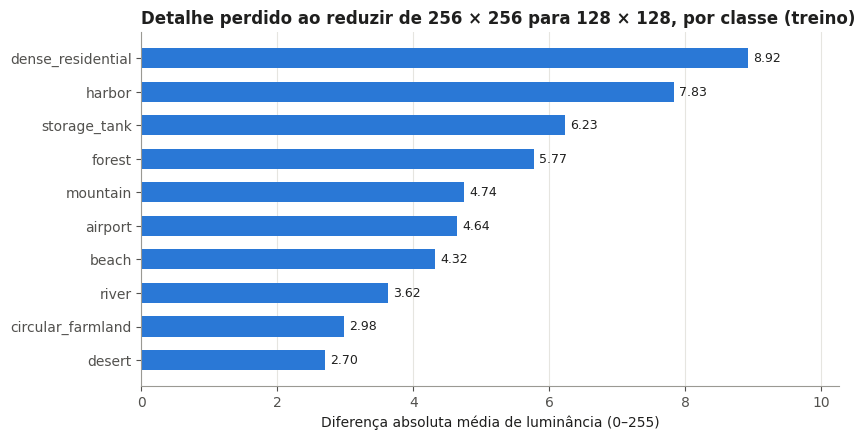

,mean,median,std
classe,,,
airport,4.64,4.47,1.59
beach,4.32,3.81,2.42
circular_farmland,2.98,2.76,1.07
dense_residential,8.92,8.94,2.59
desert,2.70,2.32,1.58
forest,5.77,5.26,1.94
harbor,7.83,7.89,2.67
mountain,4.74,4.16,2.22
river,3.62,3.42,1.47


In [15]:
perda = est.groupby("classe").perda_detalhe_128.agg(["mean", "median", "std"]).reindex(CLASSES)
ordem = perda["mean"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.6))
yy = np.arange(len(ordem))[::-1]
ax.barh(yy, ordem.values, height=0.6, color=COR, zorder=2)
ax.xaxis.grid(True, zorder=0)
for yi, v in zip(yy, ordem.values):
    ax.text(v + 0.08, yi, f"{v:.2f}", va="center", fontsize=9)
ax.set_yticks(yy, ordem.index)
ax.set_xlabel("Diferença absoluta média de luminância (0–255)")
ax.set_xlim(0, ordem.max() * 1.15)
ax.set_title("Detalhe perdido ao reduzir de 256 × 256 para 128 × 128, por classe (treino)")
salvar(fig, "perda_detalhe_resolucao.png")
plt.show()
perda.round(3).to_csv(TAB / "perda_detalhe_resolucao.csv")
display(perda.round(2))

### 6.1. Interpretação

**Observações dos painéis (mesma imagem, só a resolução muda):**

- **Composição geral:** em 128 × 128, todas as cenas continuam reconhecíveis no conjunto. A pista, o grupo de tanques, a marina, os pivôs e a mancha de floresta continuam visíveis, e a perda só fica clara nos recortes ampliados.
- **Estruturas pequenas:** são as mais afetadas. Em `harbor_003`, os barcos individuais viram manchas claras, e o espaço entre eles e os píeres some. Em `airport_634`, as aeronaves estacionadas perdem a forma de asa e viram cruzes borradas. Em `dense_residential_205`, as bordas dos telhados e os objetos menores (equipamentos, carros) ficam pouco definidos.
- **Texturas:** em `forest_186`, as copas individuais deixam de ser distinguíveis, e a textura vira um granulado sem estrutura. Nos pivôs (`circular_farmland_004`), as linhas finas de cultivo somem, mas as áreas lisas não mudam.
- **Bordas e contornos:** ficam serrilhados e mais suaves. O contorno do tanque e o anel escuro ao redor dele continuam visíveis, mas sem nitidez.
- **Padrões geométricos:** os padrões grandes se preservam bem. A forma circular dos pivôs e dos tanques grandes, a retidão das pistas e o alinhamento dos píeres continuam legíveis.

**Medida por classe:** a perda de detalhe é maior em `dense_residential` (8,9), `harbor` (7,8), `storage_tank` (6,2) e `forest` (5,8), classes cuja identidade depende de muitos elementos pequenos ou de textura fina. É menor em `desert` (2,7), `circular_farmland` (3,0) e `river` (3,6), dominadas por áreas homogêneas e estruturas grandes. Esses números descrevem só quanta informação visual a redução elimina. Não permitem afirmar nada sobre o desempenho de modelos treinados em cada resolução.

## 7. Análises complementares (opcionais, somente treino)

### 7.1. Distribuição de intensidade dos pixels
Histograma da luminância de cada classe (linha azul), com a distribuição de todas as classes juntas como referência (área cinza).

figura salva: resultados/figuras/eda/intensidade_pixels.png


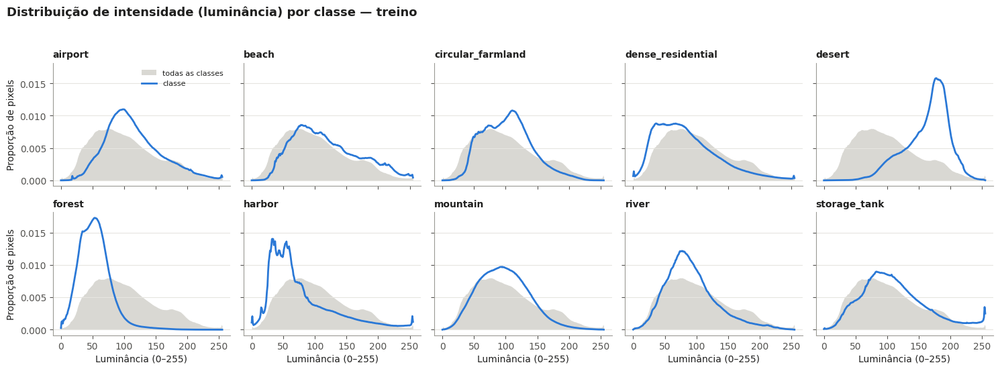

In [16]:
global_lum = sum(hist_lum.values()); global_lum = global_lum / global_lum.sum()
fig, axs = plt.subplots(2, 5, figsize=(15, 5.6), sharex=True, sharey=True)
for ax, c in zip(axs.ravel(), CLASSES):
    h = hist_lum[c] / hist_lum[c].sum()
    ax.fill_between(np.arange(256), global_lum, color="#d9d8d3", linewidth=0, label="todas as classes")
    ax.plot(np.arange(256), h, color=COR, linewidth=2, label=c)
    ax.set_title(c, fontsize=10)
    ax.yaxis.grid(True)
for ax in axs[1]: ax.set_xlabel("Luminância (0–255)")
for ax in axs[:, 0]: ax.set_ylabel("Proporção de pixels")
axs[0, 0].legend(["todas as classes", "classe"], fontsize=8, frameon=False, loc="upper right")
fig.suptitle("Distribuição de intensidade (luminância) por classe — treino", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
salvar(fig, "intensidade_pixels.png")
plt.show()

### 7.2. Distribuição dos canais RGB

figura salva: resultados/figuras/eda/histogramas_rgb.png


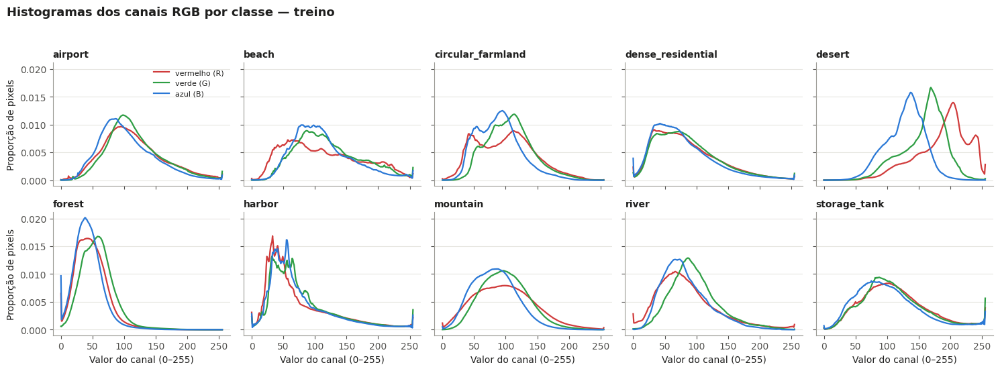

In [17]:
CORES_RGB = {"R": "#d03b3b", "G": "#2e9e44", "B": "#2a78d6"}
fig, axs = plt.subplots(2, 5, figsize=(15, 5.6), sharex=True, sharey=True)
for ax, c in zip(axs.ravel(), CLASSES):
    tot = hist_rgb[c][0].sum()
    for k, (nome, cor) in enumerate(CORES_RGB.items()):
        ax.plot(np.arange(256), hist_rgb[c][k] / tot, color=cor, linewidth=1.6, label=nome)
    ax.set_title(c, fontsize=10)
    ax.yaxis.grid(True)
for ax in axs[1]: ax.set_xlabel("Valor do canal (0–255)")
for ax in axs[:, 0]: ax.set_ylabel("Proporção de pixels")
axs[0, 0].legend(["vermelho (R)", "verde (G)", "azul (B)"], fontsize=8, frameon=False, loc="upper right")
fig.suptitle("Histogramas dos canais RGB por classe — treino", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
salvar(fig, "histogramas_rgb.png")
plt.show()

### 7.3. Variação visual dentro das classes
Para cada classe, foram escolhidas as imagens de treino mais próximas dos quantis de brilho (mínimo, Q1, mediana, Q3, máximo), para mostrar toda a amplitude de iluminação e composição dentro de uma mesma categoria.

figura salva: resultados/figuras/eda/variacao_intraclasse.png


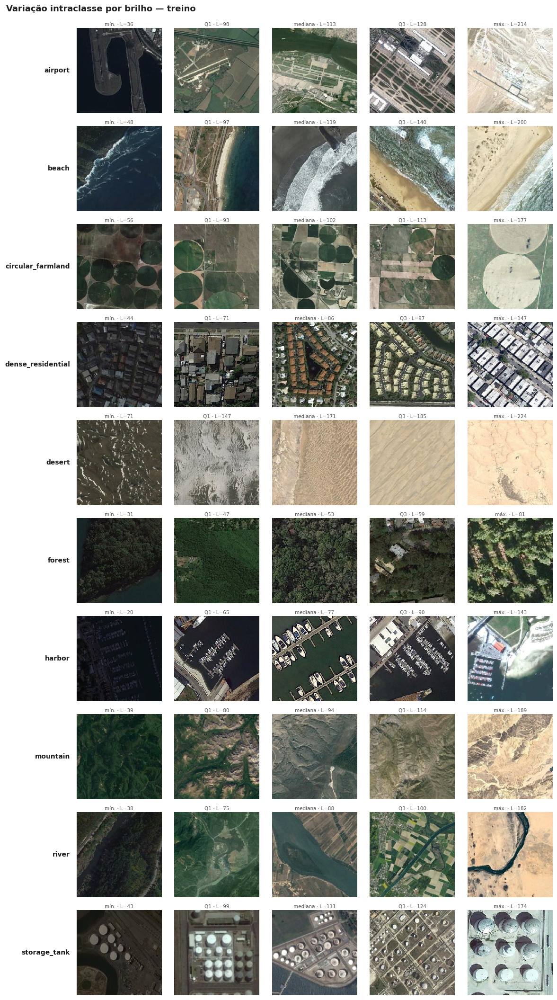

,desvio_brilho,desvio_saturacao,desvio_gradiente
classe,,,
airport,25.23,0.06,2.99
beach,28.36,0.09,3.68
circular_farmland,18.36,0.06,2.06
dense_residential,19.72,0.04,4.43
desert,28.49,0.10,3.15
forest,8.59,0.06,3.48
harbor,18.06,0.05,4.56
mountain,25.67,0.08,4.04
river,25.42,0.07,2.64


In [18]:
QUANTIS = [0, .25, .5, .75, 1]
ROT_Q = ["mín.", "Q1", "mediana", "Q3", "máx."]
fig, axs = plt.subplots(len(CLASSES), len(QUANTIS), figsize=(len(QUANTIS) * 2.1 + 1.6, len(CLASSES) * 2.15))
for i, c in enumerate(CLASSES):
    sub = est[est.classe == c]
    for j, q in enumerate(QUANTIS):
        alvo = sub.brilho.quantile(q)
        lin = sub.iloc[(sub.brilho - alvo).abs().argsort().iloc[0]]
        mostrar(axs[i, j], abrir(lin.arquivo), f"{ROT_Q[j]} · L={lin.brilho:.0f}", rotulo=c if j == 0 else None)
fig.suptitle("Variação intraclasse por brilho — treino", x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.985))
salvar(fig, "variacao_intraclasse.png")
plt.show()

var = est.groupby("classe")[["brilho", "saturacao", "gradiente"]].std().reindex(CLASSES)
var.columns = [f"desvio_{c}" for c in var.columns]
var.round(3).to_csv(TAB / "variacao_intraclasse.csv")
display(var.round(2))

### 7.4. Casos extremos (treino)
Os 4 menores arquivos (menor complexidade visual) e as 4 imagens mais escuras da partição de treino.

figura salva: resultados/figuras/eda/casos_extremos.png


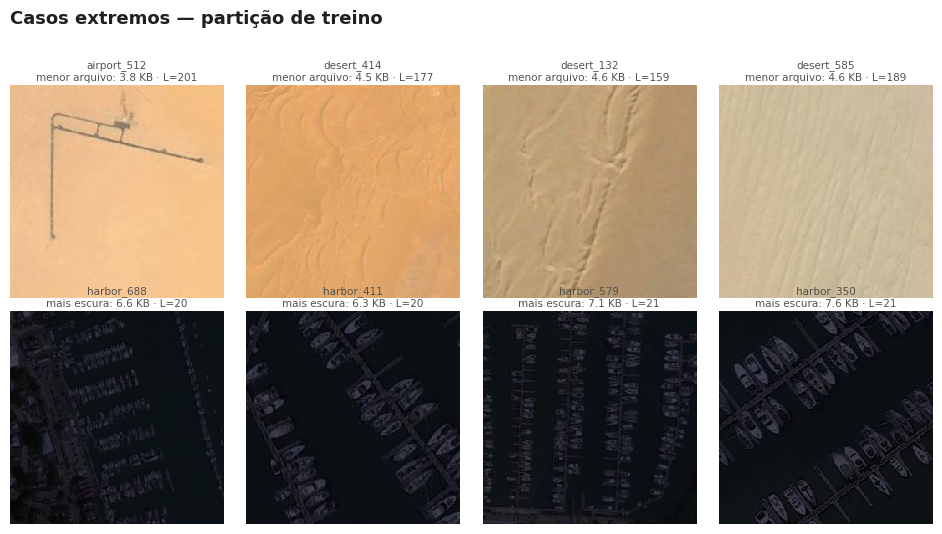

Imagens de treino com brilho médio < 35: 10 | por classe: {'forest': 6, 'harbor': 4}


In [19]:
est["bytes"] = est.arquivo.map(inv.set_index("arquivo").bytes)
extremos = [("menor arquivo", r) for r in est.nsmallest(4, "bytes").itertuples()] + \
           [("mais escura", r) for r in est.nsmallest(4, "brilho").itertuples()]
fig, axs = plt.subplots(2, 4, figsize=(4 * 2.4, 2 * 2.7))
for ax, (tipo, r) in zip(axs.ravel(), extremos):
    mostrar(ax, abrir(r.arquivo), f"{Path(r.arquivo).stem}\n{tipo}: {r.bytes/1024:.1f} KB · L={r.brilho:.0f}")
fig.suptitle("Casos extremos — partição de treino", x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
salvar(fig, "casos_extremos.png")
plt.show()
print("Imagens de treino com brilho médio < 35:", int((est.brilho < 35).sum()),
      "| por classe:", est[est.brilho < 35].classe.value_counts().to_dict())

### 7.5. Interpretação das análises complementares

- **Intensidade:** `desert` é a única classe com distribuição deslocada para valores altos, com pico estreito perto de 175. `forest` tem pico estreito e escuro, perto de 55. `harbor` tem um pico muito escuro (água, 30–60) e uma cauda longa até o branco. `harbor`, `storage_tank` e `dense_residential` têm um acúmulo de pixels em 255, que corresponde a superfícies brancas saturadas (barcos, tetos de tanques). `beach` tem a distribuição mais espalhada, porque mistura água escura e areia clara.
- **Canais RGB:** em `desert`, os três canais estão bem separados, com R > G > B, o que mostra a dominância de tons quentes. Em `forest` e `river`, o verde (G) é o canal dominante. Em `airport`, `dense_residential`, `storage_tank` e `mountain`, as curvas dos três canais quase se sobrepõem, o que indica cenas neutras e pouco saturadas. Essa sobreposição explica por que essas classes ficam próximas na matriz de distâncias.
- **Variação dentro das classes:** o painel por quantis de brilho mostra grande diversidade interna. `desert` vai de terreno escuro e manchado (L = 71) a areia quase branca (L = 224). `mountain` vai de relevo vegetado a terreno árido. `airport` inclui uma pista cercada de água muito escura (L = 36) e uma pista no deserto (L = 214). `forest` é a classe mais homogênea, com desvio do brilho de 8,6, contra cerca de 25–28 em `desert`, `beach`, `mountain`, `river` e `airport`.
- **Casos extremos:** os menores arquivos são desertos quase uniformes e a pista `airport_512`, cuja maior parte é areia. As 4 imagens mais escuras são de `harbor` (brilho médio por volta de 20) e estão subexpostas, mas os barcos e píeres continuam visíveis. Há 10 imagens de treino com brilho médio abaixo de 35: 6 de `forest` e 4 de `harbor`. Essas imagens não são inválidas, mas mostram a amplitude de iluminação que o conjunto apresenta.

## 8. Síntese

1. **Distribuição:** 7.000 imagens, 700 por classe (10% cada), perfeitamente equilibradas. As partições 70/15/15 mantêm esse equilíbrio, sem sobreposição e sem separar duplicatas.
2. **Características técnicas:** o conjunto é homogêneo. Todas as imagens são JPEG, 256 × 256, RGB de 3 canais, sem arquivos inválidos. A única pendência é a decisão sobre 6 pares de duplicatas exatas (`airport`) e 1 quase-duplicata (`mountain`).
3. **Padrões visuais:** as classes construídas se distinguem por formas (pistas, círculos, telhados, píeres) e as naturais por cor e textura. As mais características em cor e intensidade são `desert` (clara e quente) e `forest` (escura e verde). As de textura mais fina são `dense_residential` e `harbor`.
4. **Ambiguidades:** os quatro pares sugeridos têm semelhanças reais, mas restritas a subconjuntos de imagens: praias dominadas por areia, rios largos e urbanos, montanhas vegetadas, tanques grandes ou pivôs pequenos. Pelos descritores de cor e textura, os pares mais próximos são `airport` × `storage_tank` × `mountain`, que se diferenciam sobretudo pela forma. Os painéis também mostraram `desert` × `mountain` (terreno rochoso) e `airport` × `desert` (pistas em areia).
5. **Resolução:** reduzir para 128 × 128 preserva a composição geral e as formas grandes, mas elimina estruturas pequenas (barcos, aeronaves, detalhes de telhados) e texturas finas (copas). A perda é maior em `dense_residential`, `harbor`, `storage_tank` e `forest`, e menor em `desert` e `circular_farmland`.

Todas essas observações são **hipóteses descritivas**. Nesta etapa, nenhum modelo foi treinado ou avaliado.

## 9. Arquivos produzidos

| Arquivo | Conteúdo |
|---|---|
| `resultados/figuras/eda/distribuicao_classes.png` | Gráfico de barras com a frequência de cada classe |
| `resultados/figuras/eda/tamanho_arquivos.png` | Tamanho dos arquivos JPEG por classe |
| `resultados/figuras/eda/exemplos_classes.png` | 5 exemplos de treino por classe |
| `resultados/figuras/eda/distancia_classes.png` | Matriz de distância de cor e textura entre as classes |
| `resultados/figuras/eda/ambiguidades_visuais.png` (+ `ambiguidade_*_x_*.png`) | Painéis comparativos dos 4 pares |
| `resultados/figuras/eda/comparacao_resolucoes.png` | Mesma imagem em 256 × 256 e 128 × 128, com recortes |
| `resultados/figuras/eda/perda_detalhe_resolucao.png` | Detalhe perdido na redução, por classe |
| `resultados/figuras/eda/intensidade_pixels.png`, `histogramas_rgb.png`, `variacao_intraclasse.png`, `casos_extremos.png` | Análises complementares |
| `resultados/tabelas/eda/*.csv` | Tabelas de frequência, propriedades, descritores, distâncias e variação |